In [16]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from scipy import ndimage
from sklearn.cluster import KMeans


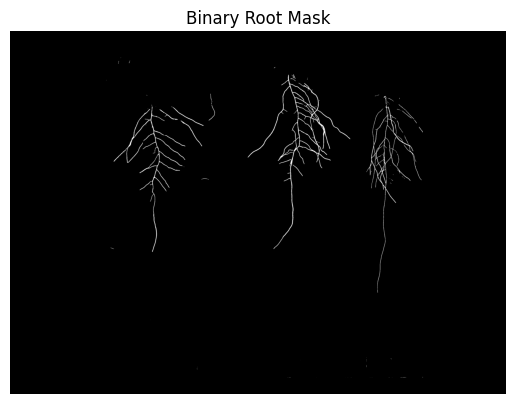

In [17]:
mask = cv2.imread('task5_test_image_prediction_Mohammadali_244437.png',
                  cv2.IMREAD_GRAYSCALE)

binary = np.zeros_like(mask, dtype=np.uint8)
binary[mask > 127] = 255

plt.imshow(binary, cmap='gray')
plt.title("Binary Root Mask")
plt.axis('off')
plt.show()

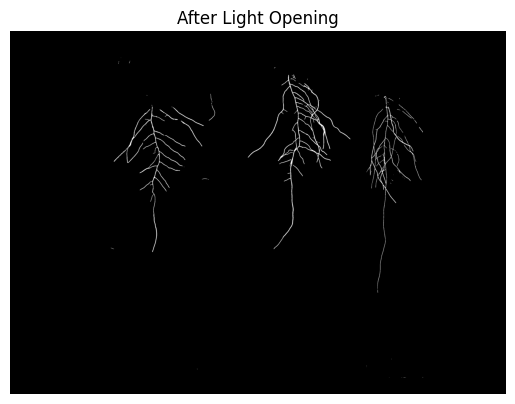

In [18]:
kernel_open = np.ones((2, 2), np.uint8)
binary_open = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel_open, iterations=1
)

plt.imshow(binary_open, cmap='gray')
plt.title("After Light Opening")
plt.axis('off')
plt.show()

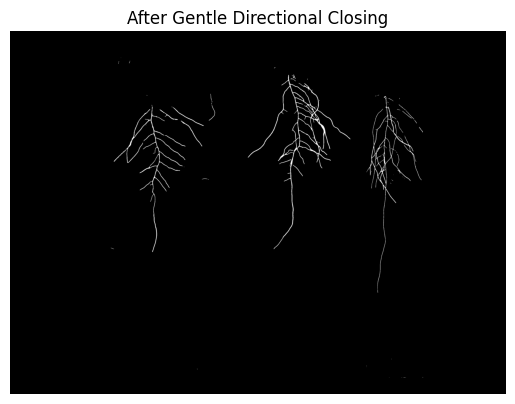

In [19]:
# Step 3 (corrected): Gentle directional closing
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 7))
binary_closed = cv2.morphologyEx(
    binary_open,
    cv2.MORPH_CLOSE,
    kernel_close,
    iterations=1
)

plt.imshow(binary_closed, cmap='gray')
plt.title("After Gentle Directional Closing")
plt.axis('off')
plt.show()


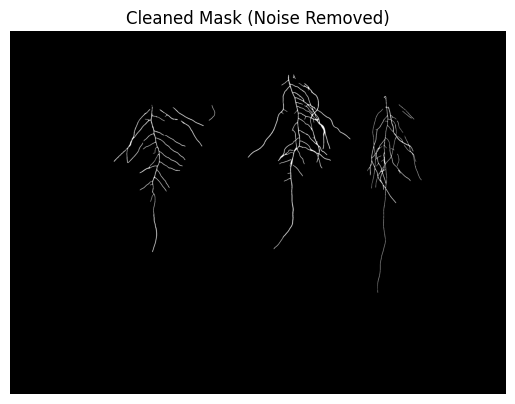

In [41]:
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_closed, connectivity=8
)

min_area = 200
clean_mask = np.zeros_like(binary_closed)

for i in range(1, num_labels):  # skip background
    if stats[i, cv2.CC_STAT_AREA] >= min_area:
        clean_mask[labels == i] = 255

plt.imshow(clean_mask, cmap='gray')
plt.title("Cleaned Mask (Noise Removed)")
plt.axis('off')
plt.show()


In [42]:
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    clean_mask, connectivity=8
)


In [43]:
boxes = []
for i in range(1, num_labels):
    x, y, w, h, _ = stats[i]
    boxes.append([x, y, x + w, y + h])



In [44]:
def boxes_overlap_or_vertical_close(b1, b2, gap_x=8, gap_y=30):
    x1, y1, x2, y2 = b1
    a1, b1_, a2, b2_ = b2

    b1e = [x1 - gap_x, y1 - gap_y, x2 + gap_x, y2 + gap_y]
    b2e = [a1 - gap_x, b1_ - gap_y, a2 + gap_x, b2_ + gap_y]

    return not (
        b1e[2] < b2e[0] or
        b2e[2] < b1e[0] or
        b1e[3] < b2e[1] or
        b2e[3] < b1e[1]
    )


In [45]:
merged_boxes = []

while boxes:
    current = boxes.pop(0)
    merged = True

    while merged:
        merged = False
        for b in boxes[:]:
            if boxes_overlap_or_vertical_close(current, b):
                current = [
                    min(current[0], b[0]),
                    min(current[1], b[1]),
                    max(current[2], b[2]),
                    max(current[3], b[3]),
                ]
                boxes.remove(b)
                merged = True

    merged_boxes.append(current)


In [46]:
merged_boxes = sorted(merged_boxes, key=lambda b: b[0])

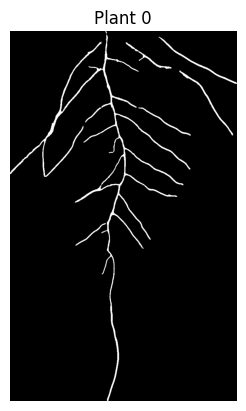

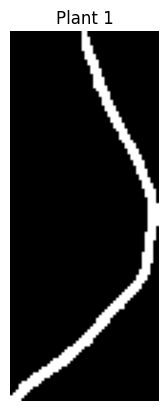

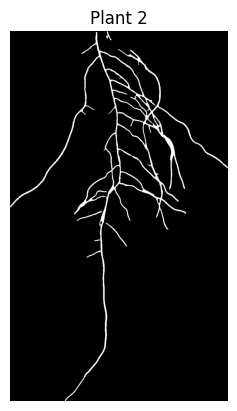

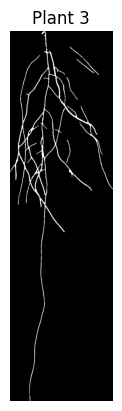

Extracted 4 plant root systems.


In [48]:
os.makedirs('final_roots_new', exist_ok=True)

plant_masks = []

for i, (x1, y1, x2, y2) in enumerate(merged_boxes):
    crop = clean_mask[y1:y2, x1:x2]
    plant_masks.append(crop)

    plt.imshow(crop, cmap='gray')
    plt.title(f"Plant {i}")
    plt.axis('off')
    plt.show()

    cv2.imwrite(f'final_roots_new/plant_{i}.png', crop)

print(f"Extracted {len(plant_masks)} plant root systems.")